In [1]:
# step1 เตรียม Environment
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore")

In [2]:
# import data
DATA_PATH = Path(
    r"C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv"
)

df = pd.read_csv(DATA_PATH)

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y",
    errors="raise"
)

numeric_columns = ["Price", "Open", "High", "Low"]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# เรียงจากอดีตไปอนาคต
df = (
    df.sort_values("Date")
      .drop_duplicates(subset="Date")
      .set_index("Date")
)

# รอบแรกใช้ Price เป็น target
price = df["Price"].dropna().astype(float)

print(df.head())
print(df.tail())
print("จำนวนข้อมูล:", len(price))
print("ช่วงเวลา:", price.index.min(), "ถึง", price.index.max())
print("Missing Price:", price.isna().sum())

             Price    Open    High     Low    Vol. Change %
Date                                                       
2022-07-01  0.9589  0.9541  0.9647  0.9536  68.09K    0.52%
2022-07-04  0.9594  0.9593  0.9601  0.9557  68.80K    0.05%
2022-07-05  0.9739  0.9598  0.9771  0.9570  85.14K    1.51%
2022-07-06  0.9822  0.9739  0.9842  0.9731  95.91K    0.85%
2022-07-07  0.9842  0.9822  0.9859  0.9783  86.85K    0.20%
             Price    Open    High     Low Vol. Change %
Date                                                    
2026-06-25  0.8796  0.8802  0.8824  0.8781  NaN   -0.09%
2026-06-26  0.8784  0.8795  0.8808  0.8745  NaN   -0.14%
2026-06-29  0.8756  0.8779  0.8789  0.8748  NaN   -0.32%
2026-06-30  0.8756  0.8756  0.8786  0.8743  NaN    0.00%
2026-07-01  0.8790  0.8756  0.8802  0.8752  NaN    0.39%
จำนวนข้อมูล: 1044
ช่วงเวลา: 2022-07-01 00:00:00 ถึง 2026-07-01 00:00:00
Missing Price: 0


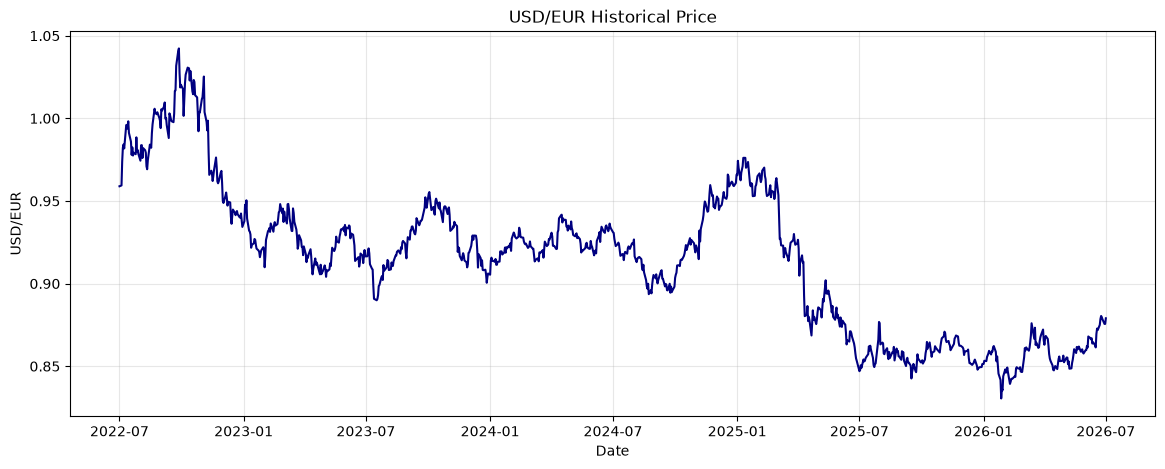

In [3]:
# ตรวจแนวโน้มกราฟของราคา
plt.figure(figsize=(14, 5))
plt.plot(price.index, price, color="navy")

plt.title("USD/EUR Historical Price")
plt.xlabel("Date")
plt.ylabel("USD/EUR")
plt.grid(alpha=0.3)
plt.show()

In [4]:
# แบ่ง Train,Validation,Test
n = len(price)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train = price.iloc[:train_end]
validation = price.iloc[train_end:validation_end]
test = price.iloc[validation_end:]

print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("Train period:", train.index.min(), "-", train.index.max())
print("Validation period:", validation.index.min(), "-", validation.index.max())
print("Test period:", test.index.min(), "-", test.index.max())

Train: 730
Validation: 157
Test: 157
Train period: 2022-07-01 00:00:00 - 2025-04-17 00:00:00
Validation period: 2025-04-18 00:00:00 - 2025-11-24 00:00:00
Test period: 2025-11-25 00:00:00 - 2026-07-01 00:00:00


In [5]:
# Stationary Check เพื่อหาค่า d
def adf_test(series, name):
    result = adfuller(
        series.dropna(),
        autolag="AIC"
    )

    print(name)
    print(f"ADF statistic: {result[0]:.6f}")
    print(f"p-value:       {result[1]:.6f}")

    if result[1] < 0.05:
        print("ผล: Stationary")
    else:
        print("ผล: ยังไม่ Stationary")

    print()


adf_test(train, "Price level")
adf_test(train.diff().dropna(), "First difference")

Price level
ADF statistic: -1.752534
p-value:       0.404269
ผล: ยังไม่ Stationary

First difference
ADF statistic: -20.430499
p-value:       0.000000
ผล: Stationary



In [6]:
# In another way ในการหาค่า d แบบอัตโนมัติ
def choose_d(series, max_d=2):
    current = series.copy()

    for d in range(max_d + 1):
        p_value = adfuller(
            current.dropna(),
            autolag="AIC"
        )[1]

        print(f"d={d}, ADF p-value={p_value:.6f}")

        if p_value < 0.05:
            return d

        current = current.diff().dropna()

    return max_d


D = choose_d(train)
print("Selected d:", D)

d=0, ADF p-value=0.404269
d=1, ADF p-value=0.000000
Selected d: 1


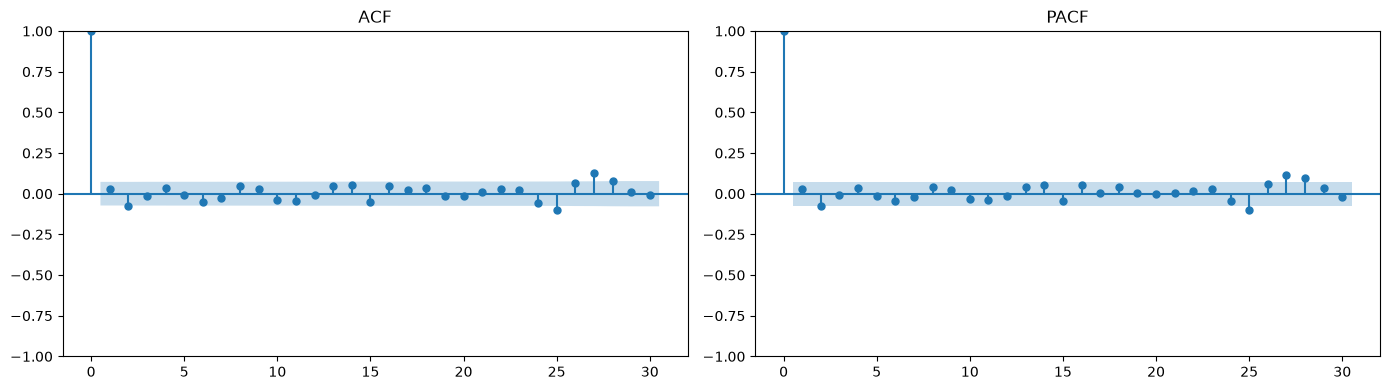

In [7]:
#
stationary_train = train.copy()

for _ in range(D):
    stationary_train = stationary_train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(
    stationary_train,
    lags=30,
    ax=axes[0]
)

plot_pacf(
    stationary_train,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[0].set_title("ACF")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

In [8]:
def rolling_forecast(train_series, evaluation_series, order):
    model = ARIMA(
        train_series.to_numpy(),
        order=order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit()
    predictions = []

    for actual in evaluation_series.to_numpy():
        next_prediction = fitted.forecast(steps=1)[0]
        predictions.append(next_prediction)

        # เพิ่มค่าจริงล่าสุดโดยยังไม่ประมาณ parameters ใหม่
        fitted = fitted.append(
            np.array([actual]),
            refit=False
        )

    return np.array(predictions)


def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": mean_absolute_percentage_error(
            actual,
            predicted
        ) * 100
    }

In [9]:
candidate_results = []

for p in range(0, 4):
    for q in range(0, 4):
        order = (p, D, q)

        try:
            validation_prediction = rolling_forecast(
                train,
                validation,
                order
            )

            metrics = calculate_metrics(
                validation.to_numpy(),
                validation_prediction
            )

            candidate_results.append({
                "order": order,
                **metrics
            })

        except Exception as error:
            print("ใช้ไม่ได้:", order, error)

results_df = (
    pd.DataFrame(candidate_results)
      .sort_values("RMSE")
      .reset_index(drop=True)
)

results_df.head(10)

,order,MAE,RMSE,MAPE (%)
0,"(0, 1, 0)",0.003061,0.003935,0.353121
1,"(0, 1, 1)",0.003070,0.003946,0.354170
2,"(1, 1, 1)",0.003071,0.003946,0.354331
3,"(1, 1, 0)",0.003072,0.003949,0.354455
4,"(1, 1, 3)",0.003079,0.003957,0.355162
5,"(0, 1, 3)",0.003079,0.003961,0.355211
6,"(1, 1, 2)",0.003089,0.003964,0.356304
7,"(2, 1, 1)",0.003086,0.003965,0.355976
8,"(3, 1, 0)",0.003086,0.003966,0.355963
9,"(3, 1, 1)",0.003086,0.003966,0.355961


In [10]:
BEST_ORDER = tuple(results_df.loc[0, "order"])

print("Best ARIMA order:", BEST_ORDER)
print(results_df.head())

Best ARIMA order: (0, 1, 0)
       order       MAE      RMSE  MAPE (%)
0  (0, 1, 0)  0.003061  0.003935  0.353121
1  (0, 1, 1)  0.003070  0.003946  0.354170
2  (1, 1, 1)  0.003071  0.003946  0.354331
3  (1, 1, 0)  0.003072  0.003949  0.354455
4  (1, 1, 3)  0.003079  0.003957  0.355162


In [11]:
train_validation = pd.concat([
    train,
    validation
])

test_prediction = rolling_forecast(
    train_validation,
    test,
    BEST_ORDER
)

arima_metrics = calculate_metrics(
    test.to_numpy(),
    test_prediction
)

print("ARIMA:", BEST_ORDER)

for metric, value in arima_metrics.items():
    print(f"{metric}: {value:.6f}")

ARIMA: (0, 1, 0)
MAE: 0.002355
RMSE: 0.003173
MAPE (%): 0.274790


In [12]:
naive_prediction = np.concatenate([
    [train_validation.iloc[-1]],
    test.iloc[:-1].to_numpy()
])

naive_metrics = calculate_metrics(
    test.to_numpy(),
    naive_prediction
)

comparison = pd.DataFrame({
    "ARIMA": arima_metrics,
    "Naive baseline": naive_metrics
})

comparison

,ARIMA,Naive baseline
MAE,0.002355,0.002355
RMSE,0.003173,0.003173
MAPE (%),0.274790,0.274790


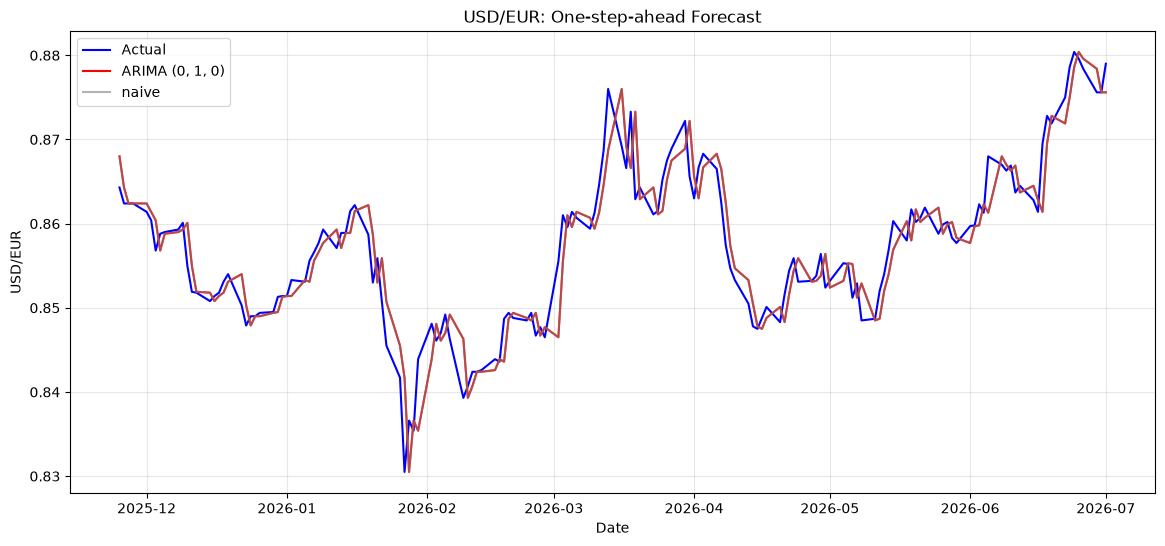

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test,
    label="Actual",
    color="blue"
)

plt.plot(
    test.index,
    test_prediction,
    label=f"ARIMA {BEST_ORDER}",
    color="red"
)

plt.plot(
    test.index,
    naive_prediction,
    label="naive",
    color="grey",
    alpha=0.6
)

plt.title("USD/EUR: One-step-ahead Forecast")
plt.xlabel("Date")
plt.ylabel("USD/EUR")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
HORIZON = 1

# Train โมเดลด้วยข้อมูลทั้งหมด
final_model = ARIMA(
    price.to_numpy(),
    order=BEST_ORDER,
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_result = final_model.fit()

# Forecast วันถัดไป
forecast_result = final_result.get_forecast(
    steps=HORIZON
)

predicted_price = float(
    np.asarray(forecast_result.predicted_mean)[0]
)

confidence_interval = np.asarray(
    forecast_result.conf_int(alpha=0.05)
)

# วันที่ทำการถัดไป
next_date = price.index[-1] + pd.offsets.BDay(1)

one_day_forecast = pd.DataFrame({
    "Date": [next_date],
    "Forecast": [predicted_price],
    "Lower 95%": [confidence_interval[0, 0]],
    "Upper 95%": [confidence_interval[0, 1]]
})

one_day_forecast

,Date,Forecast,Lower 95%,Upper 95%
0,2026-07-02,0.879,0.870306,0.887694


<!-- ADDED_ANALYSIS_MARKER_v1 -->
## เพิ่มเติม: เปรียบเทียบ split, Cross-validation, Assumption checks และ % Error

ส่วนนี้เพิ่มจากโมเดลเดิม โดยยึดหลักสำคัญสำหรับ time series คือ **เรียงตามเวลาและไม่ shuffle ข้อมูล**

- **80/20:** ใช้ 80% แรกเป็น train และ 20% หลังเป็น test; เลือก `(p,d,q)` ด้วย expanding-window cross-validation ภายใน train เท่านั้น
- **70/15/15:** ใช้ expanding-window cross-validation ภายใน train 70% เพื่อเลือก `(p,d,q)`, ใช้ 15% ถัดมาตรวจสอบ validation และเก็บ 15% สุดท้ายเป็น test
- รายงาน MAE, RMSE และ MAPE โดย MAPE คือ error ในหน่วยเปอร์เซ็นต์

> หมายเหตุ: test ของสองวิธีมีขนาดและช่วงวันที่ไม่เท่ากัน จึงควรดูทั้งเปอร์เซ็นต์ error และช่วงเวลาที่ทดสอบประกอบกัน


In [15]:
# เครื่องมือเพิ่มเติมสำหรับ model evaluation
from sklearn.model_selection import TimeSeriesSplit
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import statsmodels.api as sm

CV_SPLITS = 5
P_VALUES = range(0, 4)
Q_VALUES = range(0, 4)
EPSILON = 1e-12


def calculate_metrics_with_percentage(actual, predicted):
    """คำนวณ error ทั้งในหน่วยราคาและเปอร์เซ็นต์"""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = actual - predicted

    mape = np.mean(
        np.abs(error) / np.maximum(np.abs(actual), EPSILON)
    ) * 100
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": mape,
    }


def naive_one_step_forecast(train_series, evaluation_series):
    """Naive baseline: ค่าพรุ่งนี้เท่ากับค่าจริงล่าสุดที่ทราบ"""
    return np.concatenate([
        [train_series.iloc[-1]],
        evaluation_series.iloc[:-1].to_numpy(),
    ])


def walk_forward_cv_grid_search(series, orders, n_splits=5):
    """Expanding-window CV; ทุก validation fold อยู่หลัง training fold เสมอ"""
    splitter = TimeSeriesSplit(n_splits=n_splits)
    rows = []

    for fold, (train_index, validation_index) in enumerate(
        splitter.split(series), start=1
    ):
        fold_train = series.iloc[train_index]
        fold_validation = series.iloc[validation_index]

        for order in orders:
            try:
                prediction = rolling_forecast(
                    fold_train,
                    fold_validation,
                    order,
                )
                metrics = calculate_metrics_with_percentage(
                    fold_validation.to_numpy(),
                    prediction,
                )
                rows.append({
                    "Fold": fold,
                    "Order": order,
                    "Train size": len(fold_train),
                    "Validation size": len(fold_validation),
                    **metrics,
                })
            except Exception as error:
                print(f"CV ใช้ไม่ได้: fold={fold}, order={order}, error={error}")

    return pd.DataFrame(rows)


### 1) Expanding-window cross-validation

ภาพรวมแต่ละ fold เป็นลำดับเวลาแบบนี้: `train → validation` และ train จะขยายใหญ่ขึ้นเรื่อย ๆ จึงไม่เอาข้อมูลอนาคตย้อนกลับไปสอนโมเดล


In [16]:
# เตรียม 80/20 split แบบ chronological
n = len(price)
split_80_index = int(n * 0.80)
train_80 = price.iloc[:split_80_index]
test_20 = price.iloc[split_80_index:]

# d มาจาก ADF บน train 70% เดิม จึงไม่ได้เห็นข้อมูล test
candidate_orders_cv = [
    (p, D, q)
    for p in P_VALUES
    for q in Q_VALUES
]

cv_fold_results = walk_forward_cv_grid_search(
    train_80,
    candidate_orders_cv,
    n_splits=CV_SPLITS,
)

cv_summary = (
    cv_fold_results
    .groupby("Order", as_index=False)
    .agg(
        folds=("Fold", "nunique"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        mean_MAPE_pct=("MAPE (%)", "mean"),
        std_MAPE_pct=("MAPE (%)", "std"),
    )
    .sort_values(["mean_RMSE", "mean_MAPE_pct"])
    .reset_index(drop=True)
)

BEST_ORDER_CV = tuple(cv_summary.loc[0, "Order"])

print("Best order จาก 5-fold time-series CV:", BEST_ORDER_CV)
display(cv_summary.head(10).round(6))


Best order จาก 5-fold time-series CV: (0, 1, 3)


,Order,folds,mean_MAE,mean_RMSE,mean_MAPE_pct,std_MAPE_pct
0,"(0, 1, 3)",5,0.003145,0.004104,0.343183,0.073382
1,"(3, 1, 0)",5,0.003147,0.004106,0.343449,0.073570
2,"(3, 1, 1)",5,0.003147,0.004106,0.343450,0.073568
3,"(2, 1, 1)",5,0.003148,0.004106,0.343457,0.073586
4,"(0, 1, 2)",5,0.003149,0.004107,0.343616,0.073597
5,"(2, 1, 2)",5,0.003145,0.004107,0.343248,0.074079
6,"(1, 1, 2)",5,0.003149,0.004108,0.343662,0.073609
7,"(2, 1, 0)",5,0.003150,0.004108,0.343716,0.073733
8,"(0, 1, 0)",5,0.003151,0.004110,0.343792,0.071670
9,"(1, 1, 1)",5,0.003154,0.004110,0.344077,0.071772


### 2) Expanding-window cross-validation สำหรับ 70/15/15

ทำ 5-fold CV ภายใน **Train 70% เท่านั้น** เพื่อเลือก `(p,d,q)` จากนั้นใช้ Validation 15% ตรวจสอบโมเดล และยังไม่แตะ Test 15%


In [17]:
# Cross-validation ภายใน train 70% ของโครงสร้าง 70/15/15
cv_fold_results_70 = walk_forward_cv_grid_search(
    train,
    candidate_orders_cv,
    n_splits=CV_SPLITS,
)

cv_summary_70 = (
    cv_fold_results_70
    .groupby("Order", as_index=False)
    .agg(
        folds=("Fold", "nunique"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        mean_MAPE_pct=("MAPE (%)", "mean"),
        std_MAPE_pct=("MAPE (%)", "std"),
    )
    .sort_values(["mean_RMSE", "mean_MAPE_pct"])
    .reset_index(drop=True)
)

BEST_ORDER_CV_70 = tuple(cv_summary_70.loc[0, "Order"])

# ตรวจสอบ order ที่ CV เลือกกับ validation 15%
validation_prediction_cv_70 = rolling_forecast(
    train,
    validation,
    BEST_ORDER_CV_70,
)
validation_metrics_cv_70 = calculate_metrics_with_percentage(
    validation.to_numpy(),
    validation_prediction_cv_70,
)

print("Best order จาก 5-fold CV ภายใน train 70%:", BEST_ORDER_CV_70)
display(cv_summary_70.head(10).round(6))
display(pd.DataFrame([validation_metrics_cv_70], index=["Validation 15%"]).round(6))


Best order จาก 5-fold CV ภายใน train 70%: (2, 1, 1)


,Order,folds,mean_MAE,mean_RMSE,mean_MAPE_pct,std_MAPE_pct
0,"(2, 1, 1)",5,0.003122,0.004067,0.336870,0.073385
1,"(0, 1, 3)",5,0.003124,0.004069,0.337025,0.073573
2,"(3, 1, 1)",5,0.003126,0.004072,0.337225,0.073787
3,"(3, 1, 0)",5,0.003126,0.004072,0.337229,0.073788
4,"(0, 1, 2)",5,0.003126,0.004072,0.337252,0.073816
5,"(2, 1, 0)",5,0.003127,0.004072,0.337313,0.073908
6,"(0, 1, 0)",5,0.003132,0.004073,0.337873,0.074897
7,"(1, 1, 2)",5,0.003129,0.004077,0.337616,0.073784
8,"(0, 1, 1)",5,0.003141,0.004079,0.338772,0.075619
9,"(1, 1, 1)",5,0.003139,0.004079,0.338649,0.075722


,MAE,RMSE,MAPE (%)
Validation 15%,0.003086,0.003965,0.355976


### 3) เปรียบเทียบ 80/20 กับ 70/15/15

ทั้งสองแถวเป็นผลจาก **test set ที่โมเดลไม่เคยเห็นตอนเลือกพารามิเตอร์** และมี naive forecast เป็น baseline ให้เทียบ


In [18]:
# ----- Strategy A: 80/20 -----
# order ถูกเลือกจาก CV ภายใน train 80% เท่านั้น
prediction_80_20 = rolling_forecast(
    train_80,
    test_20,
    BEST_ORDER_CV,
)
metrics_80_20 = calculate_metrics_with_percentage(
    test_20.to_numpy(),
    prediction_80_20,
)
naive_80_20 = naive_one_step_forecast(train_80, test_20)
naive_metrics_80_20 = calculate_metrics_with_percentage(
    test_20.to_numpy(),
    naive_80_20,
)

# ----- Strategy B: 70/15/15 -----
# order ถูกเลือกจาก 5-fold CV ภายใน train 70%; validation 15% ใช้ตรวจสอบแล้ว
train_85 = pd.concat([train, validation])
prediction_70_15_15 = rolling_forecast(
    train_85,
    test,
    BEST_ORDER_CV_70,
)
metrics_70_15_15 = calculate_metrics_with_percentage(
    test.to_numpy(),
    prediction_70_15_15,
)
naive_70_15_15 = naive_one_step_forecast(train_85, test)
naive_metrics_70_15_15 = calculate_metrics_with_percentage(
    test.to_numpy(),
    naive_70_15_15,
)

split_comparison = pd.DataFrame([
    {
        "Split": "80/20",
        "Selection": f"{CV_SPLITS}-fold expanding CV",
        "Order": BEST_ORDER_CV,
        "Train/Val/Test": f"{len(train_80)}/0/{len(test_20)}",
        "Test start": test_20.index.min().date(),
        "Test end": test_20.index.max().date(),
        **metrics_80_20,
        "RMSE better than naive (%)": (
            100
            * (naive_metrics_80_20["RMSE"] - metrics_80_20["RMSE"])
            / naive_metrics_80_20["RMSE"]
        ),
    },
    {
        "Split": "70/15/15",
        "Selection": f"{CV_SPLITS}-fold expanding CV (train 70%)",
        "Order": BEST_ORDER_CV_70,
        "Train/Val/Test": f"{len(train)}/{len(validation)}/{len(test)}",
        "Test start": test.index.min().date(),
        "Test end": test.index.max().date(),
        **metrics_70_15_15,
        "RMSE better than naive (%)": (
            100
            * (naive_metrics_70_15_15["RMSE"] - metrics_70_15_15["RMSE"])
            / naive_metrics_70_15_15["RMSE"]
        ),
    },
])

display(split_comparison.round(6))

for _, row in split_comparison.iterrows():
    print(
        f"{row['Split']}: MAPE = {row['MAPE (%)']:.3f}% | "
        f"RMSE = {row['RMSE']:.6f}"
    )


,Split,Selection,Order,Train/Val/Test,Test start,Test end,MAE,RMSE,MAPE (%),RMSE better than naive (%)
0,80/20,5-fold expanding CV,"(0, 1, 3)",835/0/209,2025-09-12,2026-07-01,0.002326,0.003082,0.271372,-0.275645
1,70/15/15,5-fold expanding CV (train 70%),"(2, 1, 1)",730/157/157,2025-11-25,2026-07-01,0.002362,0.003187,0.275543,-0.443385


80/20: MAPE = 0.271% | RMSE = 0.003082
70/15/15: MAPE = 0.276% | RMSE = 0.003187


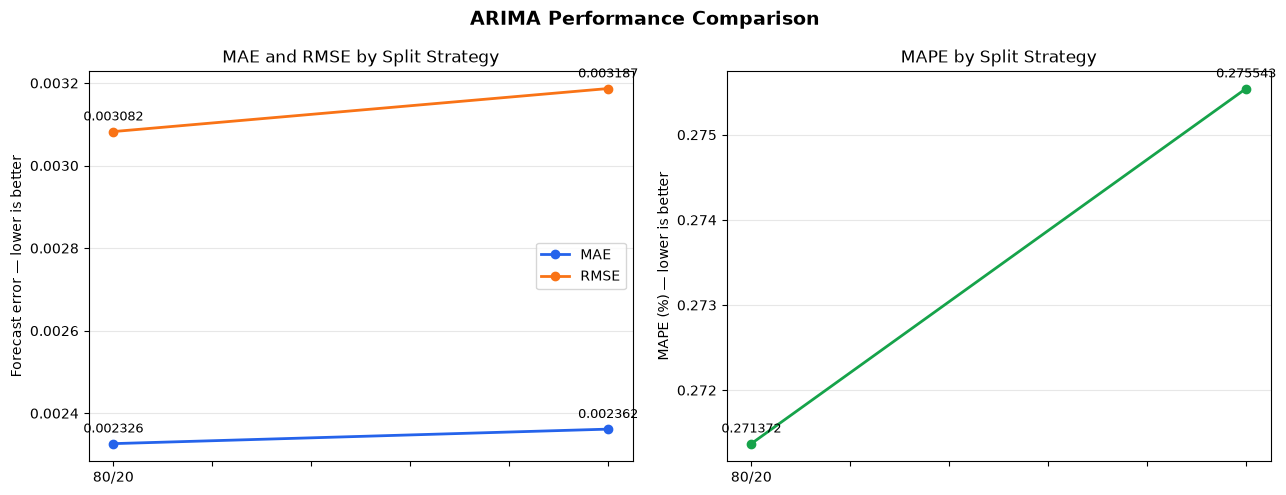

In [19]:
# กราฟเปรียบเทียบประสิทธิภาพของ 80/20 กับ 70/15/15
plot_data = split_comparison.set_index("Split")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# MAE และ RMSE มีหน่วยเดียวกับอัตราแลกเปลี่ยน จึงแสดงร่วมกันได้
plot_data[["MAE", "RMSE"]].plot(
    kind="line",
    ax=axes[0],
    color=["#2563eb", "#f97316"],
    marker="o",
    linewidth=2,
)
axes[0].set_title("MAE and RMSE by Split Strategy")
axes[0].set_ylabel("Forecast error — lower is better")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

# MAPE เป็นเปอร์เซ็นต์ จึงแยกอีกกราฟเพื่อไม่ให้สเกลปะปนกัน
plot_data[["MAPE (%)"]].plot(
    kind="line",
    ax=axes[1],
    color=["#16a34a"],
    marker="o",
    linewidth=2,
    legend=False,
)
axes[1].set_title("MAPE by Split Strategy")
axes[1].set_ylabel("MAPE (%) — lower is better")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

# แสดงค่ากำกับที่แต่ละจุดบนกราฟเส้น
for ax in axes:
    for line in ax.lines:
        for x, y in zip(line.get_xdata(), line.get_ydata()):
            ax.annotate(
                f"{y:.6f}",
                (x, y),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=9,
            )

fig.suptitle("ARIMA Performance Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 4) เปรียบเทียบค่าจริงกับค่าพยากรณ์ ARIMA ของทั้งสองวิธี

กราฟนี้ใช้เฉพาะช่วง Test ที่ 80/20 และ 70/15/15 มีวันที่ตรงกัน เพื่อให้เปรียบเทียบค่าพยากรณ์บนข้อมูลจริงชุดเดียวกัน โดยทั้งสองเส้นเป็นการพยากรณ์ล่วงหน้า 1 วันแบบ walk-forward


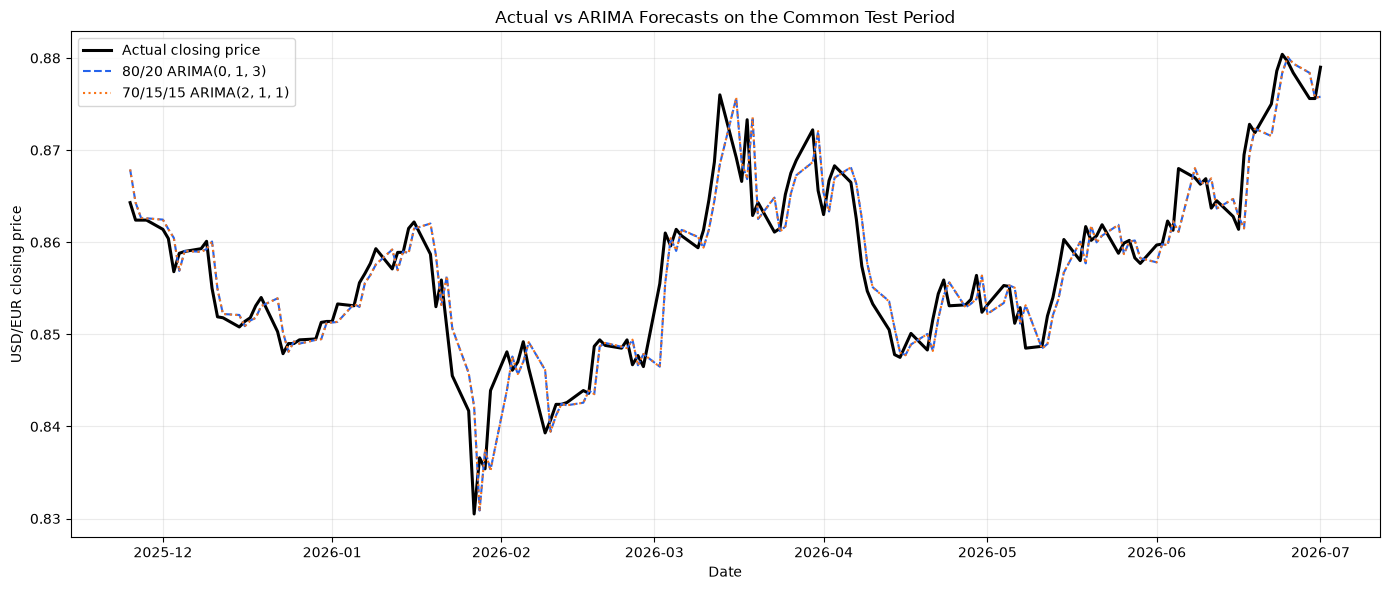

Common test period: 2025-11-25 to 2026-07-01


In [20]:
# จัดค่าพยากรณ์ของแต่ละ split ให้มี Date index
forecast_80_20_series = pd.Series(
    prediction_80_20,
    index=test_20.index,
    name=f"80/20 ARIMA{BEST_ORDER_CV}",
)
forecast_70_15_15_series = pd.Series(
    prediction_70_15_15,
    index=test.index,
    name=f"70/15/15 ARIMA{BEST_ORDER_CV_70}",
)

# inner join ทำให้เหลือเฉพาะวันที่ที่ทั้งสองวิธีพยากรณ์ร่วมกัน
forecast_comparison = pd.concat(
    [
        price.rename("Actual closing price"),
        forecast_80_20_series,
        forecast_70_15_15_series,
    ],
    axis=1,
    join="inner",
).dropna()

plt.figure(figsize=(14, 6))
plt.plot(
    forecast_comparison.index,
    forecast_comparison["Actual closing price"],
    label="Actual closing price",
    color="black",
    linewidth=2.2,
)
plt.plot(
    forecast_comparison.index,
    forecast_comparison[forecast_80_20_series.name],
    label=forecast_80_20_series.name,
    color="#2563eb",
    linewidth=1.5,
    linestyle="--",
)
plt.plot(
    forecast_comparison.index,
    forecast_comparison[forecast_70_15_15_series.name],
    label=forecast_70_15_15_series.name,
    color="#f97316",
    linewidth=1.5,
    linestyle=":",
)
plt.title("Actual vs ARIMA Forecasts on the Common Test Period")
plt.xlabel("Date")
plt.ylabel("USD/EUR closing price")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Common test period:",
    forecast_comparison.index.min().date(),
    "to",
    forecast_comparison.index.max().date(),
)


### 5) ตรวจ assumptions ของ ARIMA — ทั้ง 80/20 และ 70/15/15

ตรวจ residuals ของโมเดลทั้งสองกลยุทธ์ โดยใช้เฉพาะข้อมูลก่อน test:

- **80/20:** fit `ARIMA(0,1,3)` ที่เลือกด้วย CV บน train 80%
- **70/15/15:** fit ARIMA order ที่เลือกด้วย 5-fold CV ภายใน train 70% บน train+validation 85%
- **ADF:** series หลัง differencing ต้อง stationary (`p < 0.05`)
- **Ljung–Box:** residuals ไม่ควรมี autocorrelation เหลืออยู่ (`p > 0.05`)
- **Jarque–Bera:** residuals ควรใกล้ normal หากต้องการตีความช่วงความเชื่อมั่นแบบปกติ (`p > 0.05`)
- **ARCH LM:** residual variance ควรค่อนข้างคงที่ (`p > 0.05`)
- **AR/MA roots:** modulus ควรมากกว่า 1

> Assumptions เป็นคุณสมบัติของ residuals จากโมเดลที่ fit แล้ว จึงต้องตรวจแยกสำหรับแต่ละ split/model การไม่ผ่าน normality เพียงอย่างเดียวไม่ได้ทำให้ point forecast ใช้ไม่ได้ แต่ confidence interval อาจไม่น่าเชื่อถือเท่าที่ควร


In [21]:
def run_arima_diagnostics(training_series, order, model_name):
    """Fit ARIMA ก่อนช่วง test แล้วคืนผล assumption checks และ residuals"""
    model = ARIMA(
        training_series.to_numpy(),
        order=order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    result = model.fit()

    # ตัด residual ช่วงต้นที่ได้รับผลจาก initialization มากที่สุด
    burn_in = max(5, sum(order) + 1)
    residuals = pd.Series(
        np.asarray(result.resid),
        index=training_series.index,
        name="Residual",
    ).iloc[burn_in:].dropna()

    # Stationarity หลัง differencing ตามค่า d ของโมเดล
    stationary_series = training_series.copy()
    for _ in range(order[1]):
        stationary_series = stationary_series.diff().dropna()
    adf_pvalue = adfuller(stationary_series, autolag="AIC")[1]

    diagnostic_lag = min(10, max(1, len(residuals) // 5))
    ljung_box_pvalue = acorr_ljungbox(
        residuals,
        lags=[diagnostic_lag],
        return_df=True,
    )["lb_pvalue"].iloc[0]
    _, jb_pvalue = jarque_bera(residuals)
    _, arch_pvalue, _, _ = het_arch(
        residuals,
        nlags=diagnostic_lag,
    )

    # ถ้าไม่มี AR หรือ MA term ให้ถือว่าผ่านโดยโครงสร้าง
    ar_roots = np.asarray(result.arroots)
    ma_roots = np.asarray(result.maroots)
    min_ar_root = np.min(np.abs(ar_roots)) if ar_roots.size else np.inf
    min_ma_root = np.min(np.abs(ma_roots)) if ma_roots.size else np.inf

    checks = pd.DataFrame([
        {
            "Check": "Stationarity after differencing (ADF)",
            "Statistic": "p-value",
            "Value": adf_pvalue,
            "Pass rule": "p < 0.05",
            "Pass": adf_pvalue < 0.05,
        },
        {
            "Check": f"Residual independence (Ljung-Box lag {diagnostic_lag})",
            "Statistic": "p-value",
            "Value": ljung_box_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": ljung_box_pvalue > 0.05,
        },
        {
            "Check": "Residual normality (Jarque-Bera)",
            "Statistic": "p-value",
            "Value": jb_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": jb_pvalue > 0.05,
        },
        {
            "Check": f"Constant variance (ARCH LM lag {diagnostic_lag})",
            "Statistic": "p-value",
            "Value": arch_pvalue,
            "Pass rule": "p > 0.05",
            "Pass": arch_pvalue > 0.05,
        },
        {
            "Check": "AR roots outside unit circle",
            "Statistic": "minimum |root|",
            "Value": min_ar_root,
            "Pass rule": "|root| > 1",
            "Pass": min_ar_root > 1,
        },
        {
            "Check": "MA roots outside unit circle",
            "Statistic": "minimum |root|",
            "Value": min_ma_root,
            "Pass rule": "|root| > 1",
            "Pass": min_ma_root > 1,
        },
    ])
    checks.insert(0, "Model / split", model_name)
    checks.insert(1, "Order", [order] * len(checks))
    checks["Result"] = np.where(checks["Pass"], "PASS", "FAIL")
    return checks, residuals, result


# 80/20: fit เฉพาะ train 80%; test 20% ยังไม่ถูกใช้
assumptions_80_20, residuals_80_20, diagnostic_result_80_20 = (
    run_arima_diagnostics(
        train_80,
        BEST_ORDER_CV,
        "80/20",
    )
)

# 70/15/15: fit train+validation 85%; test 15% ยังไม่ถูกใช้
assumptions_70_15_15, residuals_70_15_15, diagnostic_result_70_15_15 = (
    run_arima_diagnostics(
        train_85,
        BEST_ORDER_CV_70,
        "70/15/15",
    )
)

assumption_results = pd.concat(
    [assumptions_80_20, assumptions_70_15_15],
    ignore_index=True,
)

display(
    assumption_results[
        [
            "Model / split",
            "Order",
            "Check",
            "Statistic",
            "Value",
            "Pass rule",
            "Result",
        ]
    ].round({"Value": 6})
)

# ตารางสั้นสำหรับเทียบ PASS/FAIL ระหว่างสองวิธี
assumption_comparison = assumption_results.pivot(
    index="Check",
    columns="Model / split",
    values="Result",
)
display(assumption_comparison)

for model_name, model_checks in assumption_results.groupby("Model / split"):
    # Normality แยกออกจาก assumptions หลักของ point forecast
    critical_checks = model_checks.loc[
        model_checks["Check"] != "Residual normality (Jarque-Bera)",
        "Pass",
    ]
    conclusion = (
        "ผ่าน assumptions หลักทั้งหมด"
        if critical_checks.all()
        else "มี assumptions หลักที่ไม่ผ่าน"
    )
    print(f"{model_name}: {conclusion}")


,Model / split,Order,Check,Statistic,Value,Pass rule,Result
0,80/20,"(0, 1, 3)",Stationarity after differencing (ADF),p-value,0.000000,p < 0.05,PASS
1,80/20,"(0, 1, 3)",Residual independence (Ljung-Box lag 10),p-value,0.893758,p > 0.05,PASS
2,80/20,"(0, 1, 3)",Residual normality (Jarque-Bera),p-value,0.000000,p > 0.05,FAIL
3,80/20,"(0, 1, 3)",Constant variance (ARCH LM lag 10),p-value,0.000000,p > 0.05,FAIL
4,80/20,"(0, 1, 3)",AR roots outside unit circle,minimum |root|,inf,|root| > 1,PASS
5,80/20,"(0, 1, 3)",MA roots outside unit circle,minimum |root|,2.823353,|root| > 1,PASS
6,70/15/15,"(2, 1, 1)",Stationarity after differencing (ADF),p-value,0.000000,p < 0.05,PASS
7,70/15/15,"(2, 1, 1)",Residual independence (Ljung-Box lag 10),p-value,0.829784,p > 0.05,PASS
8,70/15/15,"(2, 1, 1)",Residual normality (Jarque-Bera),p-value,0.000000,p > 0.05,FAIL
9,70/15/15,"(2, 1, 1)",Constant variance (ARCH LM lag 10),p-value,0.000000,p > 0.05,FAIL


Model / split,70/15/15,80/20
Check,,
AR roots outside unit circle,PASS,PASS
Constant variance (ARCH LM lag 10),FAIL,FAIL
MA roots outside unit circle,PASS,PASS
Residual independence (Ljung-Box lag 10),PASS,PASS
Residual normality (Jarque-Bera),FAIL,FAIL
Stationarity after differencing (ADF),PASS,PASS


70/15/15: มี assumptions หลักที่ไม่ผ่าน
80/20: มี assumptions หลักที่ไม่ผ่าน


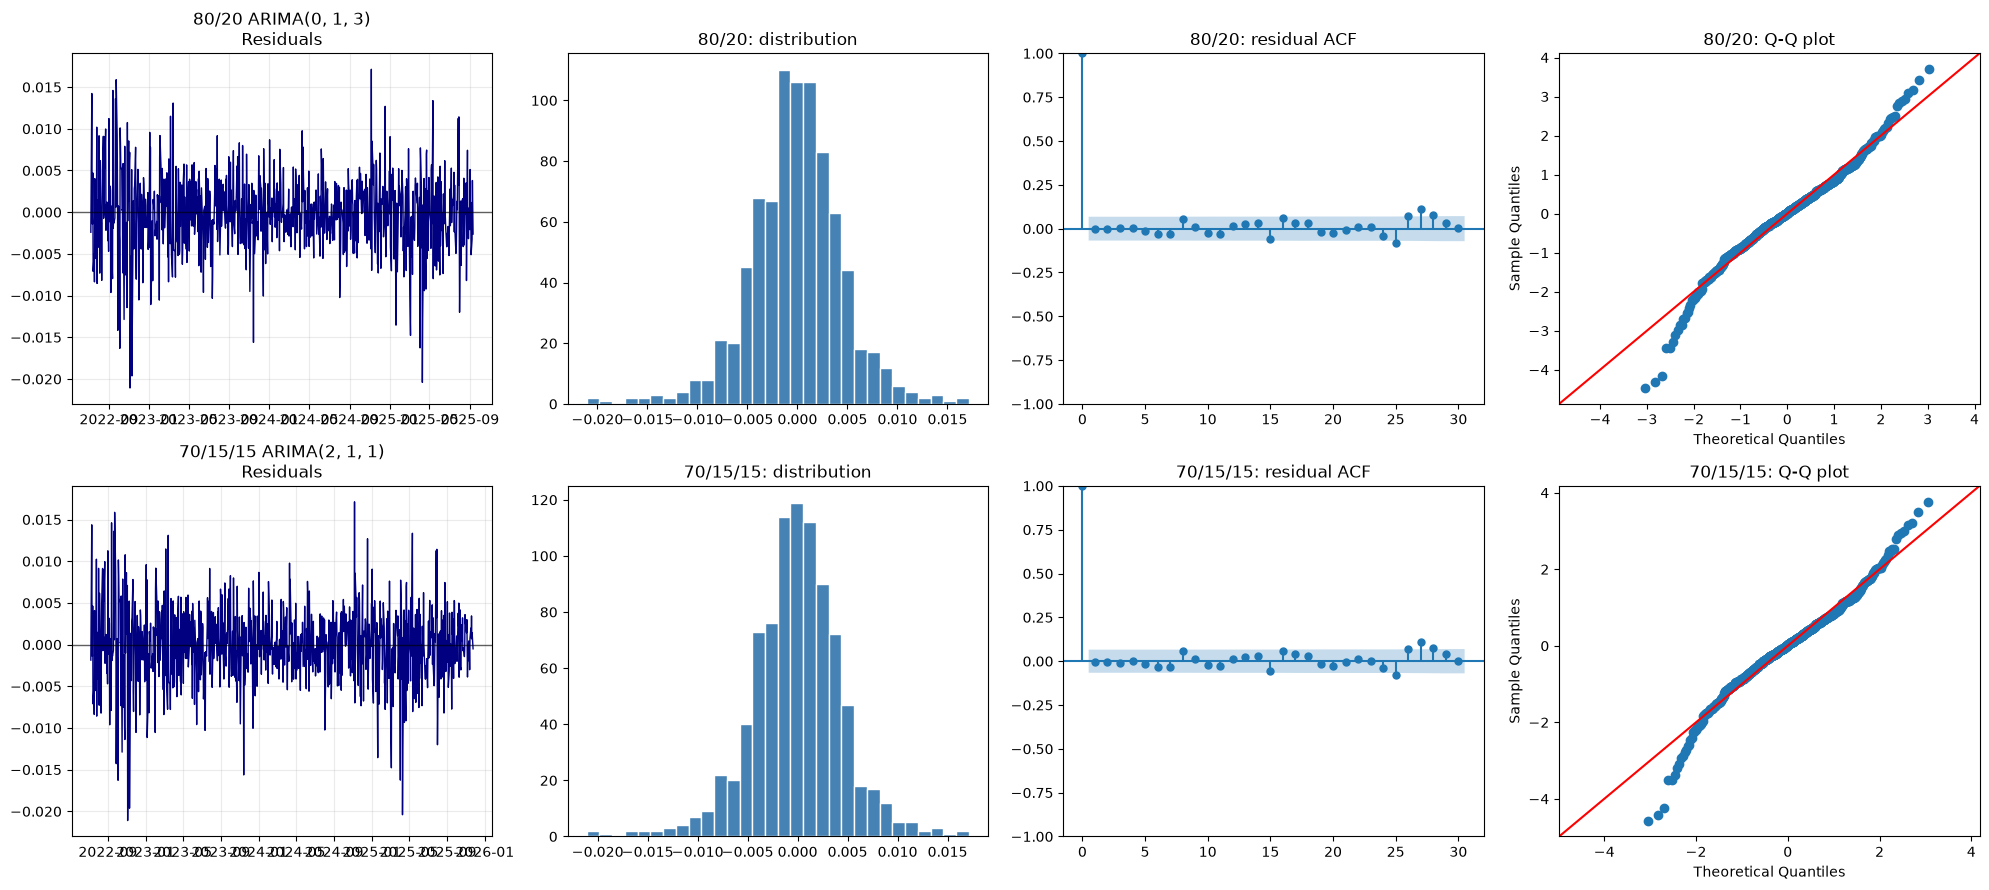

In [22]:
# Residual plots ของทั้งสอง split เพื่อเทียบกันโดยตรง
diagnostic_plot_data = [
    ("80/20", BEST_ORDER_CV, residuals_80_20),
    ("70/15/15", BEST_ORDER_CV_70, residuals_70_15_15),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for row, (split_name, order, residuals) in enumerate(diagnostic_plot_data):
    axes[row, 0].plot(
        residuals.index,
        residuals,
        color="navy",
        linewidth=1,
    )
    axes[row, 0].axhline(0, color="black", linewidth=1, alpha=0.6)
    axes[row, 0].set_title(f"{split_name} ARIMA{order}\nResiduals")
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].hist(
        residuals,
        bins=30,
        color="steelblue",
        edgecolor="white",
    )
    axes[row, 1].set_title(f"{split_name}: distribution")

    plot_acf(
        residuals,
        lags=min(30, max(1, len(residuals) // 4)),
        ax=axes[row, 2],
    )
    axes[row, 2].set_title(f"{split_name}: residual ACF")

    sm.qqplot(residuals, line="45", ax=axes[row, 3], fit=True)
    axes[row, 3].set_title(f"{split_name}: Q-Q plot")

plt.tight_layout()
plt.show()


ผ### วิธีอ่านผลแบบสั้น

1. ดู `MAPE (%)` ในตารางเปรียบเทียบ: เช่น `0.80` หมายถึงโดยเฉลี่ยพยากรณ์คลาดเคลื่อนประมาณ **0.80%**
2. ค่า error ยิ่งต่ำยิ่งดี แต่ควรดู `RMSE better than naive (%)` ด้วย: ค่าบวกแปลว่า ARIMA ดีกว่า naive baseline; ค่าลบแปลว่า naive ยังดีกว่า
3. ในตาราง assumptions ถ้า Ljung–Box ไม่ผ่าน แปลว่า residual ยังมี pattern เหลืออยู่ ควรลองเพิ่ม/ลด `p, q` หรือเพิ่ม seasonal/exogenous terms
4. ถ้า ARCH LM ไม่ผ่าน อาจพิจารณา ARIMA + GARCH; ถ้าเฉพาะ Jarque–Bera ไม่ผ่าน ให้ระวังการตีความ confidence interval
